In [2]:
import numpy as np
import random
import matplotlib.pyplot as plt

I want to know why this already seems to work like I would expect it to work...?


[0. 0. 1. 1. 0. 0. 1. 0. 0. 1. 1. 0. 0. 1. 0. 0. 0. 0. 0. 1. 0. 1. 0. 0.
 1. 0. 0. 1. 0. 1. 1. 1. 1. 0. 1. 0. 1. 0. 1. 1. 0. 1. 0. 0. 0. 0. 1. 0.
 1. 0. 0. 1. 1. 1. 0. 0. 1. 1. 0. 1. 0. 0. 1. 1. 0. 1. 0. 1. 1. 0. 0. 0.
 0. 0. 0. 1. 0. 1. 0. 1. 1. 1. 1. 0. 1. 1. 0. 1. 0. 0. 1. 1. 1. 0. 1. 1.
 0. 1. 0. 0. 0. 1. 0. 1. 1. 0. 1. 1. 1. 0. 0. 1. 1. 1. 0. 1. 1. 0. 1. 0.
 1. 1. 1. 1. 1. 0. 1. 0. 1. 0. 1. 0. 1. 1. 0. 0. 1. 0. 0. 1. 0. 0. 0. 0.
 1. 1. 1. 0. 1. 1. 0. 0. 1. 0. 0. 1. 0. 0. 1. 1. 0. 0. 0. 1. 0. 0. 0. 1.
 1. 0. 0. 1. 1. 0. 0. 0. 1. 1. 1. 1. 0. 1. 1. 0. 0. 1. 0. 0. 0. 0. 1. 1.
 1. 0. 0. 0. 1. 0. 1. 1. 1. 0. 0. 1. 0. 1. 0. 0. 1. 0. 0. 1. 1. 0. 1. 1.
 0. 0. 0. 1. 0. 1. 1. 0. 0. 1. 1. 0. 0. 1. 1. 1. 1. 0. 1. 1. 0. 1. 1. 0.
 1. 1. 0. 1. 1. 0. 0. 0. 1. 1. 1. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0.
 1. 0. 1. 0. 1. 0. 0. 0. 1. 0. 0. 1. 1. 1. 1. 0. 0. 1. 0. 1. 0. 1. 1. 0.
 0. 0. 1. 1. 0. 0. 0. 0. 1. 1. 1. 1. 1. 1. 0. 0. 1. 1. 0. 1. 1. 1. 0. 1.
 0. 0. 1. 0. 0. 1. 1. 0. 1. 0. 0. 0. 1. 0. 0. 1. 0.

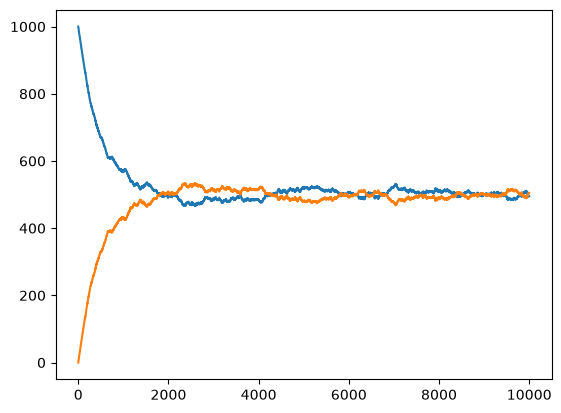

In [14]:
N = 1000                # number of particles
t_max = 10000               # number of steps
time_step = 1          # step interval

pstate = np.zeros(N)   # state vector
time_points = np.arange(0, t_max, time_step)
left_points = []
right_points = []

# Main Loop
for i in range(t_max):
    
    n = np.count_nonzero(pstate == 0)
    
    n_right = np.count_nonzero(pstate == 1)
    
    left_points.append(n)
    right_points.append(n_right)
    
    rnd = np.random.choice(N)

    if pstate[rnd] == 0:
        if np.random.random() < (n / N):
            pstate[rnd] = 1
    else:
        if np.random.random() < (1 - (n / N)):
            pstate[rnd] = 0

print(pstate)

# Plotting
plt.plot(time_points, left_points)
plt.plot(time_points, right_points)

So my reasoning is that I create an array that represents the state of the system at t=0. All the particles are on the left (0) side of the box, and the idea is that we will select an entry of this array pstate[i] at random (which is the same as selecting a particle at random), calculate its probability to cross to the right side, and if it does, update its state to 1. IF the state of the system is 0, we calculate its probability of moving over to the right as n/N. IF the state of the system is 1, we calculate it's probability of moving over to the left using 1 - n/N. \
\
At every step of the way, I need to "count" how many entries are in state 0. I also want to plot this number over time. \
\
How the hell do I determine when to stop the loop?? (ie. when equilibrium has been reached).\
\
Well, I first I will define the number of steps (t = # steps).
N as we know is the number of particles.

